Importing the dependencies

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression , LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

Data Collection and Processing

In [47]:
#Loading data and doing initial analysis
df = pd.read_csv("Failure data.csv")
df.head(15)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


In [48]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [49]:
#Check missing values
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

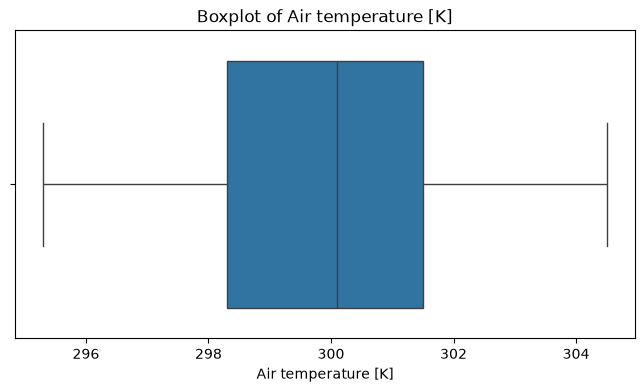

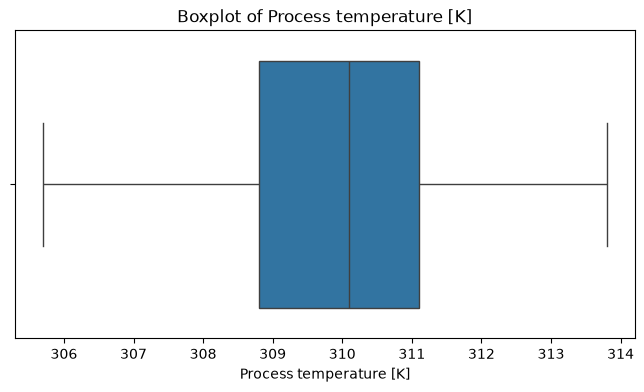

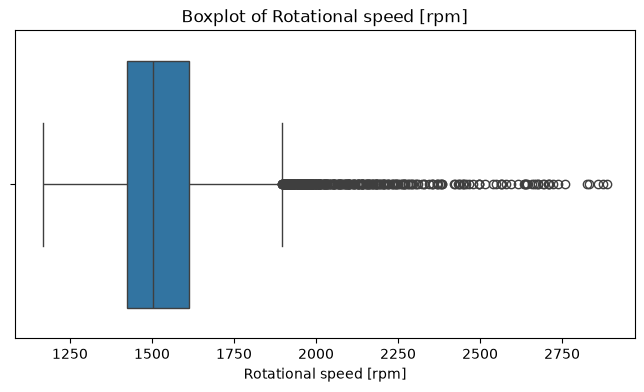

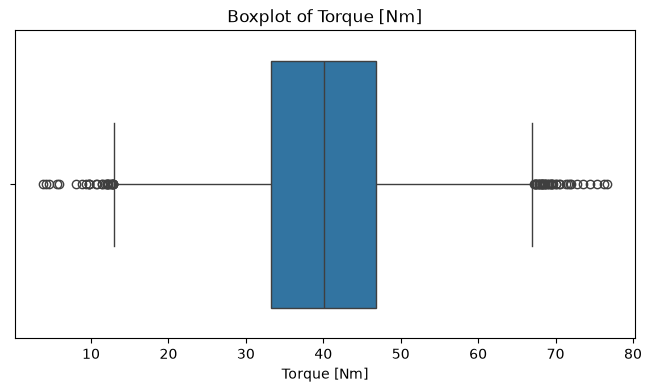

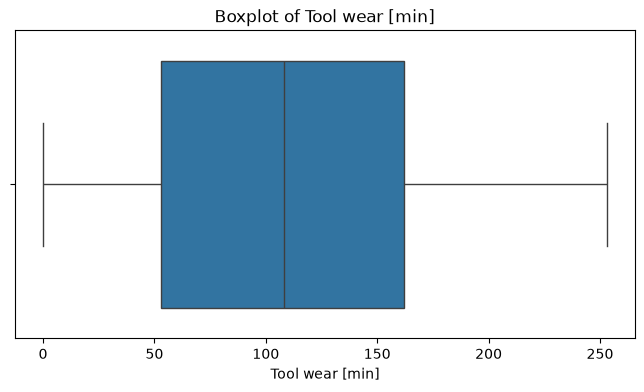

In [50]:
#Box plot for columns with numerical values
num_col =  [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

for col in num_col:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

<Axes: >

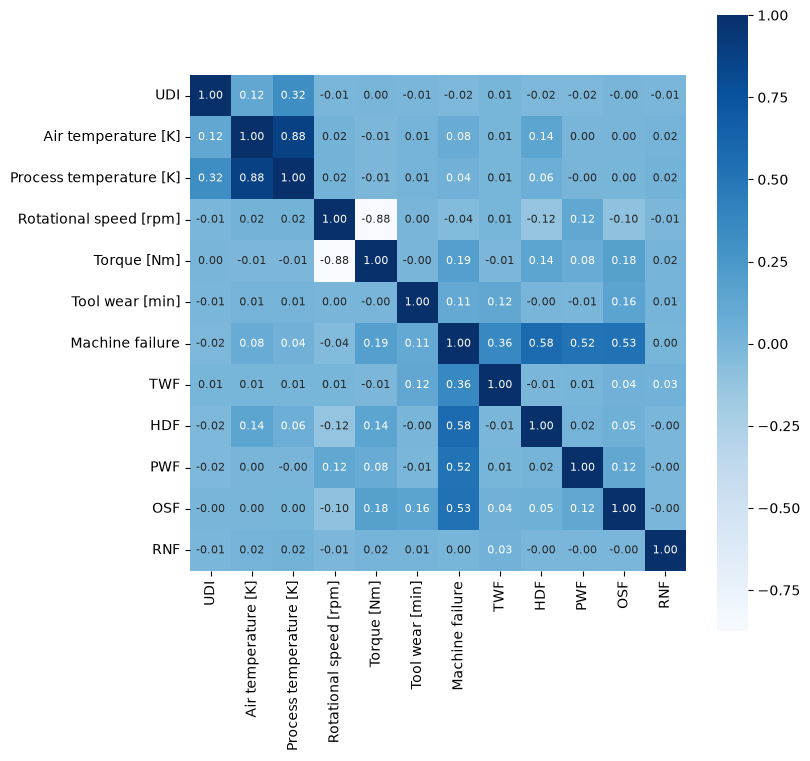

In [51]:
#Correlation using heatmap
correlation = df.corr(numeric_only=True)
plt.figure(figsize = (8, 8))
sns.heatmap(correlation, cbar=True, square=True, fmt='.2f', annot = True, annot_kws={'size': 8}, cmap = 'Blues')

In [52]:
#Dummy encoding for Columns type
df["Type"].unique()


<ArrowStringArray>
['M', 'L', 'H']
Length: 3, dtype: str

In [53]:
df.head(20)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


In [54]:
df = pd.get_dummies(df , columns= ["Type"] , drop_first = True)


In [56]:
print(df["Type_L"].value_counts())
print(df["Type_M"].value_counts())


Type_L
True     6000
False    4000
Name: count, dtype: int64
Type_M
False    7003
True     2997
Name: count, dtype: int64


In [62]:
#Removing insignificant columns
X = df.drop(columns=[
    'UDI',
    'Product ID',
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF',
    'Machine failure'
    ])
X

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
0,298.1,308.6,1551,42.8,0,False,True
1,298.2,308.7,1408,46.3,3,True,False
2,298.1,308.5,1498,49.4,5,True,False
3,298.2,308.6,1433,39.5,7,True,False
4,298.2,308.7,1408,40.0,9,True,False
...,...,...,...,...,...,...,...
9995,298.8,308.4,1604,29.5,14,False,True
9996,298.9,308.4,1632,31.8,17,False,False
9997,299.0,308.6,1645,33.4,22,False,True
9998,299.0,308.7,1408,48.5,25,False,False


In [63]:
Y = df['Machine failure']


Splitting the data

In [73]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=42)

In [66]:
print(X.shape, X_train.shape, X_test.shape)

(10000, 7) (8000, 7) (2000, 7)


In [74]:
Y_train.value_counts()

Machine failure
0    7729
1     271
Name: count, dtype: int64

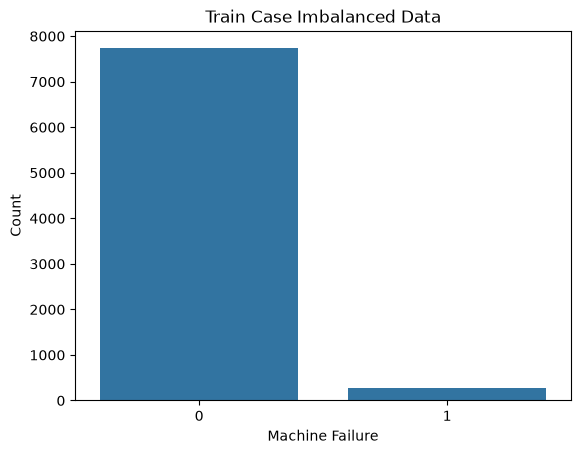

In [79]:

sns.countplot(x=Y_train)

plt.title("Train Case Imbalanced Data")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.show()

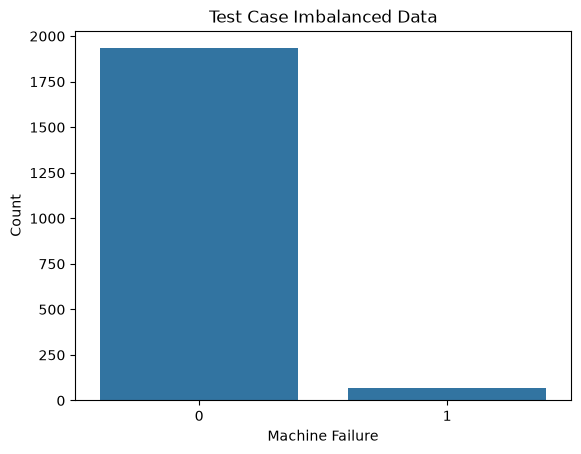

In [80]:

sns.countplot(x=Y_test)

plt.title("Test Case Imbalanced Data")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.show()

In [88]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled)
print(X_test_scaled)

[[ 0.99891359  0.60428162 -0.46060741 ... -0.84399726 -1.23436595
   1.53620728]
 [-1.50519408 -1.15325984 -0.77557391 ...  0.38226308 -1.23436595
   1.53620728]
 [ 0.49809206  1.07746586 -1.00765448 ...  0.46086951 -1.23436595
   1.53620728]
 ...
 [ 0.14751698  1.00986812 -0.41640159 ... -1.23702942 -1.23436595
  -0.65095382]
 [ 0.84866713  0.80707487 -0.12353801 ...  0.08355864  0.81013252
  -0.65095382]
 [-0.65379747 -0.20689136 -0.42745305 ... -1.63006158  0.81013252
  -0.65095382]]
[[ 0.24768129 -0.13929361 -1.07396322 ...  0.71241009  0.81013252
  -0.65095382]
 [ 1.85031019  1.61824785 -0.14564092 ...  0.42942694  0.81013252
  -0.65095382]
 [ 1.24932436  0.94227037  0.10854256 ...  1.59280213  0.81013252
  -0.65095382]
 ...
 [-0.95429039 -1.42365083 -0.51586469 ...  0.20932893 -1.23436595
   1.53620728]
 [ 1.1992422   1.28025911 -0.64848216 ...  1.35698283 -1.23436595
   1.53620728]
 [-1.0544547  -0.6800756   2.37961675 ... -1.11125913 -1.23436595
   1.53620728]]


Machine Learning Models

Logistics Regresssion

In [94]:
lr_model = LogisticRegression()


In [95]:
lr_model.fit(X_train_scaled, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [97]:
X_train_pred = lr_model.predict(X_train_scaled)
X_test_pred = lr_model.predict(X_test_scaled)

In [108]:
lr_acc = accuracy_score(X_test_pred, Y_test)
lr_prec = precision_score(X_test_pred, Y_test)
lr_recall = recall_score(X_test_pred, Y_test)

In [109]:
print("The accuracy score for Logistic Regression is:", lr_acc)
print("The precision score for Logistic Regression is:", lr_prec)
print("The recall score for Logistic Rgression is",lr_recall)

The accuracy score for Logistic Regression is: 0.9675
The precision score for Logistic Regression is: 0.10294117647058823
The recall score for Logistic Rgression is 0.6363636363636364


Decision Tree

In [110]:
dt_model = DecisionTreeClassifier(random_state=42)


In [111]:
dt_model.fit(X_train_scaled, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [116]:
X_train_pred_dt = dt_model.predict(X_train_scaled)
X_test_pred_dt = dt_model.predict(X_test_scaled)

In [117]:
dt_acc = accuracy_score(X_test_pred_dt, Y_test)
dt_prec = precision_score(X_test_pred_dt, Y_test)
dt_recall = recall_score(X_test_pred_dt, Y_test)

In [123]:
print("The accuracy score for Decision Tree is:", dt_acc)
print("The precision score for Decision Tree is:", dt_prec)
print("The recall score for Decision Tree is",dt_recall)

The accuracy score for Decision Tree is: 0.978
The precision score for Decision Tree is: 0.6617647058823529
The recall score for Decision Tree is 0.6818181818181818


Random Forest

In [119]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [121]:
X_train_pred_rf = rf_model.predict(X_train_scaled)
X_test_pred_rf = rf_model.predict(X_test_scaled)

In [122]:
rf_acc = accuracy_score(X_test_pred_rf, Y_test)
rf_prec = precision_score(X_test_pred_rf, Y_test)
rf_recall = recall_score(X_test_pred_rf, Y_test)

In [125]:
print("The accuracy score for Random Forest Classifier is:", rf_acc)
print("The precision score for Random Forest Classifier is:", rf_prec)
print("The recall score for Random Forest Classifier is",rf_recall)

The accuracy score for Random Forest Classifier is: 0.9815
The precision score for Random Forest Classifier is: 0.5294117647058824
The recall score for Random Forest Classifier is 0.8780487804878049


XGBoost

In [126]:
from xgboost import XGBClassifier

In [128]:
xgb_model = XGBClassifier(  random_state=42,
    eval_metric="logloss")
xgb_model.fit(X_train_scaled, Y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [130]:
X_train_pred_xgb = xgb_model.predict(X_train_scaled)
X_test_pred_xgb = xgb_model.predict(X_test_scaled)

In [131]:
xgb_acc = accuracy_score(X_test_pred_xgb, Y_test)
xgb_prec = precision_score(X_test_pred_xgb, Y_test)
xgb_recall = recall_score(X_test_pred_xgb, Y_test)

In [132]:
print("The accuracy score for XG Boost is:", xgb_acc)
print("The precision score for XG Boost is:", xgb_prec)
print("The recall score for XG Boost is",xgb_recall)

The accuracy score for XG Boost is: 0.9875
The precision score for XG Boost is: 0.7205882352941176
The recall score for XG Boost is 0.8909090909090909


(0.0, 120.0)

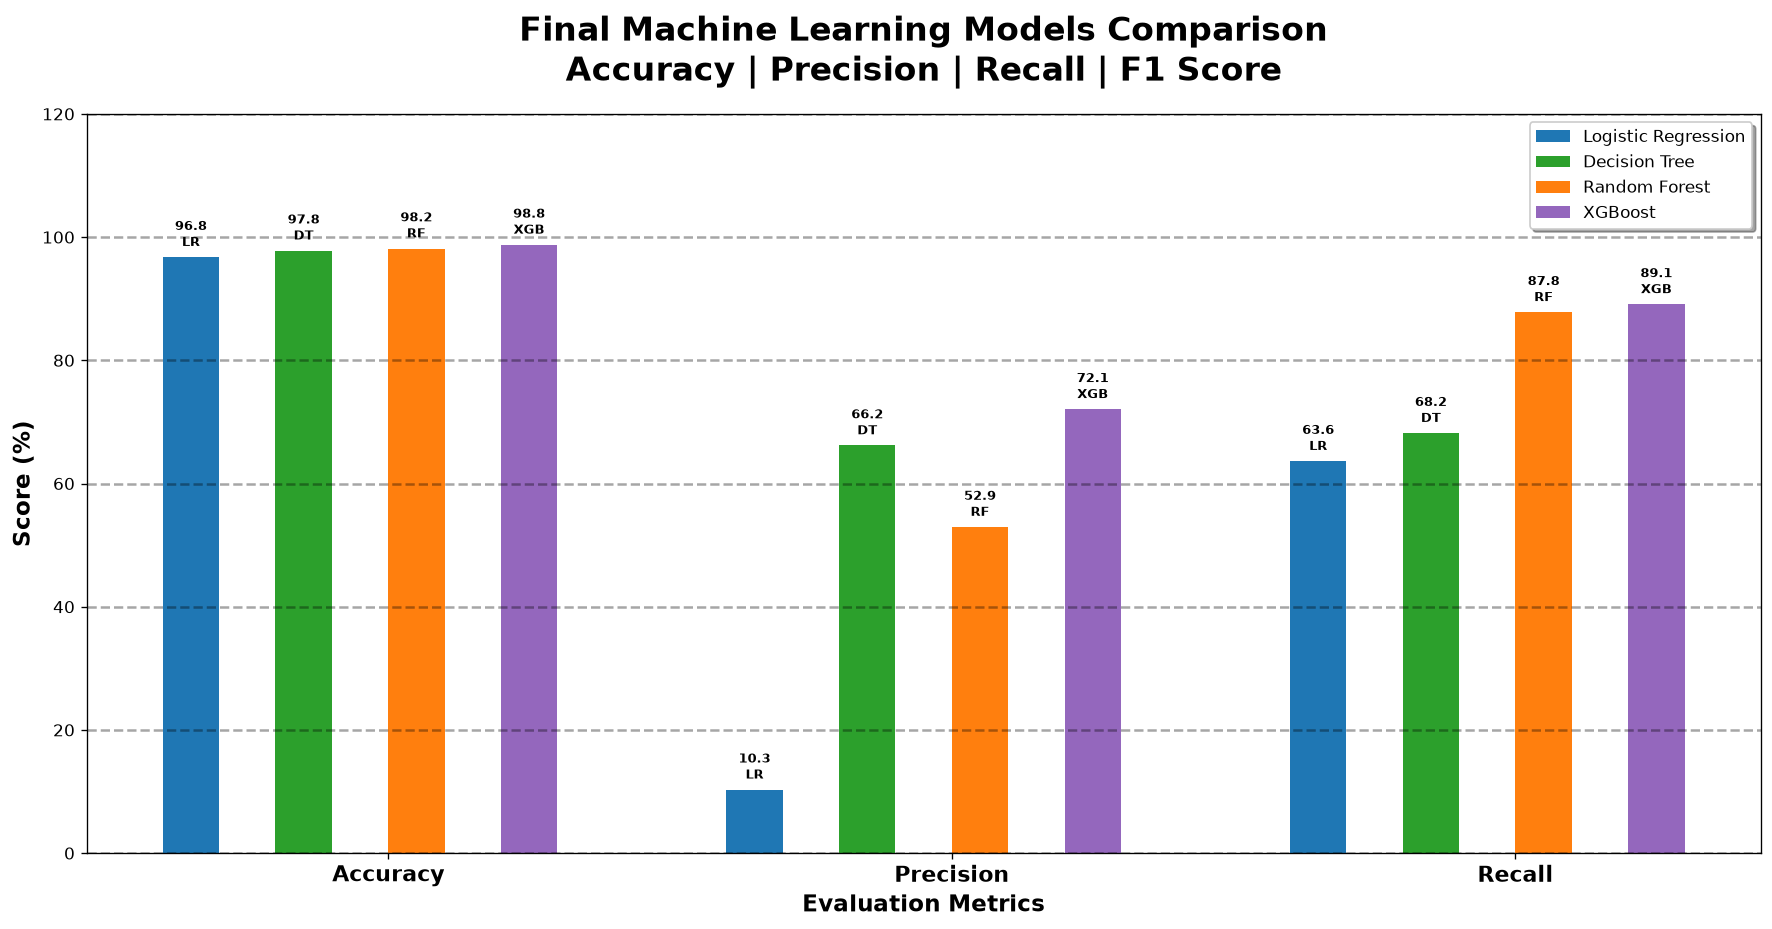

In [134]:
metrics = ["Accuracy", "Precision", "Recall"]

# Data from individual model evaluations
# Collect all the metric values into a dictionary
data = {
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        lr_acc,
        dt_acc,
        rf_acc,
        xgb_acc,
    ],
    'Precision': [
        lr_prec,
        dt_prec,
        rf_prec,
        xgb_prec
    ],
    'Recall': [
        lr_recall,
        dt_recall,
        rf_recall,
        xgb_recall,
    ]
    
    
}

comparison_df = pd.DataFrame(data)

# -------------------------
# Data from comparison_df
# -------------------------
lr = comparison_df.iloc[0][metrics].values
dt = comparison_df.iloc[1][metrics].values
rf = comparison_df.iloc[2][metrics].values
xgb = comparison_df.iloc[3][metrics].values


# Convert into percentage
lr = lr * 100
dt = dt * 100
rf = rf * 100
xgb = xgb * 100


# -------------------------
# X-axis
# -------------------------
x = np.arange(len(metrics))
width = 0.10

# -------------------------
# Professional Color Palette
# -------------------------
colors = [
    "#1F77B4",   # Logistic Regression

    "#2CA02C",   # Decision Tree

    "#FF7F0E",   # Random Forest

    "#9467BD",   # XGBoost

]

# -------------------------
# Figure
# -------------------------
plt.figure(figsize=(18,8), dpi=120)

bars1 = plt.bar(x-3.5*width, lr, width,
                color=colors[0], label="Logistic Regression")


bars2 = plt.bar(x-1.5*width, dt, width,
                color=colors[1], label="Decision Tree")



bars3 = plt.bar(x+0.5*width, rf, width,
                color=colors[2], label="Random Forest")



bars4 = plt.bar(x+2.5*width, xgb, width,
                color=colors[3], label="XGBoost")


# -------------------------
# Value Labels
# -------------------------
for bars in [bars1,bars2,bars3,bars4]:
    labels = [
    "LR",
    "DT",
    "RF",
    "XGB"
]

bars_list = [
    bars1,bars2,bars3,bars4
]

for bars, short in zip(bars_list, labels):

    value_labels = [
        f"{bar.get_height():.1f}\n{short}"
        for bar in bars
    ]

    plt.bar_label(
        bars,
        labels=value_labels,
        fontsize=8,
        fontweight="bold",
        padding=4
    )

# -------------------------
# Labels
# -------------------------
plt.xticks(x, metrics, fontsize=13, fontweight="bold")
plt.ylabel("Score (%)", fontsize=14, fontweight="bold")
plt.xlabel("Evaluation Metrics", fontsize=14, fontweight="bold")

# -------------------------
# Title
# -------------------------
plt.title(
    "Final Machine Learning Models Comparison\n"
    "Accuracy | Precision | Recall | F1 Score",
    fontsize=20,
    fontweight="bold",
    pad=20
)

# -------------------------
# Grid
# -------------------------
plt.grid(
    axis="y",
    linestyle="--",
    linewidth=1.5,
    alpha=0.35,
    color="#000000"
)

# -------------------------
# Legend
# -------------------------
plt.legend(
    loc="upper right",
    fontsize=10,
    frameon=True,
    fancybox=True,
    shadow=True
)

# -------------------------
# Limits
# -------------------------
plt.ylim(0,120)

# -------------------------